<a href="https://colab.research.google.com/github/Jesus-Aguirre1/JESUS_2053240_ACTS_IA/blob/main/UU/ACTIVIDADES/AF8_Redes_Neuronales_Convolucionales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Martes N4-N6**

Jesus Román Aguirre Hernandez 2053240

Jair Eduardo Benavides García 2052989

Sarahi Montserrat Barba Botello 204150

Raúl Alejandro Garza Elizondo 2066224

El código implementa una red neuronal convolucional (CNN) para clasificar

imágenes del conjunto de datos MNIST, que contiene dígitos manuscritos del 0 al 9. Primero se cargan y preprocesan los datos, normalizando los valores de los píxeles y ajustando las dimensiones de las imágenes para adaptarlas al modelo.

La red se construye con capas convolucionales y de pooling para extraer características, seguidas de capas densas para realizar la clasificación final mediante softmax. Se utiliza el optimizador Adam y la función de pérdida Sparse Categorical Crossentropy, evaluando el desempeño con la exactitud (accuracy).

Finalmente, se entrena, evalúa y prueban las predicciones del modelo sobre imágenes de prueba, mostrando tanto los valores reales como las predicciones para analizar su rendimiento.

In [1]:
#1.Cargar librerías
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#2.Cargar datos
(train_data, train_labels), (test_data, test_labels) = datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
#Se añadio dimensión de canal para compatibilidad
train_data = train_data.reshape((train_data.shape[0], 28, 28, 1))
test_data  = test_data.reshape((test_data.shape[0], 28, 28, 1))

In [4]:
#Nombres de las clases (0-9 dígitos)
class_names = [str(i) for i in range(10)]

In [5]:
# 3.Preprocesamiento de datos
# Normalizar a rango [0,1]
train_data = train_data.astype('float32') / 255.0
test_data  = test_data.astype('float32')  / 255.0

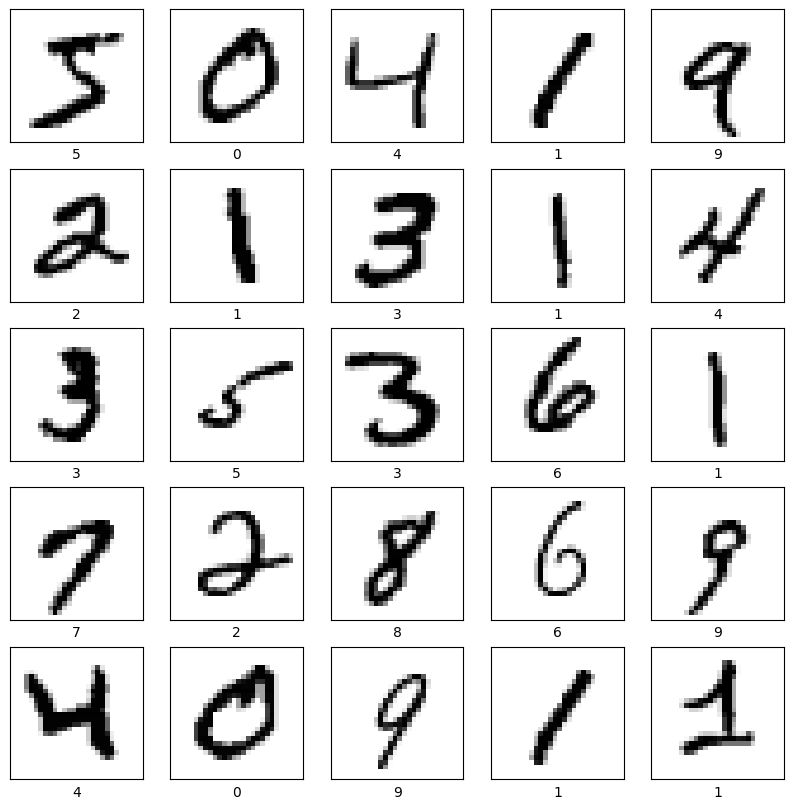

In [7]:
#Mostrar algunas imágenes de entrenamiento
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_data[i].reshape(28,28), cmap=plt.cm.binary)
    plt.xlabel(class_names[train_labels[i]])
plt.show()

In [8]:
#4. Selección y entrenamiento del modelo
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [11]:
epochs = 10
history = model.fit(train_data, train_labels, epochs=epochs,
                    validation_data=(test_data, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 54s 28ms/step - accuracy: 0.8994 - loss: 0.3269 - val_accuracy: 0.9860 - val_loss: 0.0444
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 51s 27ms/step - accuracy: 0.9847 - loss: 0.0474 - val_accuracy: 0.9856 - val_loss: 0.0457
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 27ms/step - accuracy: 0.9909 - loss: 0.0301 - val_accuracy: 0.9918 - val_loss: 0.0281
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 50s 27ms/step - accuracy: 0.9935 - loss: 0.0213 - val_accuracy: 0.9896 - val_loss: 0.0327
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 50s 27ms/step - accuracy: 0.9945 - loss: 0.0181 - val_accuracy: 0.9908 - val_loss: 0.0301
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 50s 27ms/step - accuracy: 0.9955 - loss: 0.0140 - val_accuracy: 0.9907 - val_loss: 0.0329
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 27ms/step - accuracy: 0.9964 - loss: 0.0120 - val_accuracy: 0.9901 - val_loss: 0.0321
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 27ms/step - accuracy: 0.9968 -

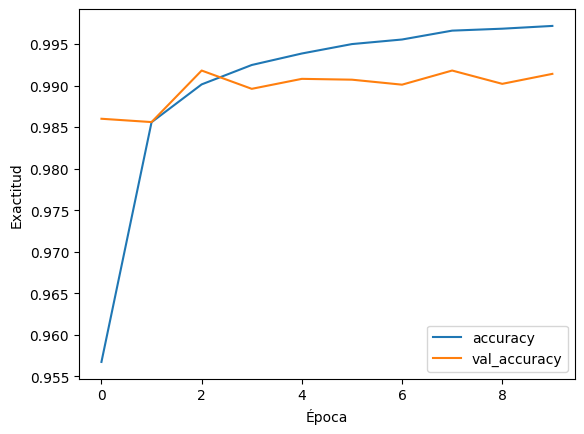

In [12]:
#Graficar exactitud
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Época')
plt.ylabel('Exactitud')
plt.legend(loc='lower right')
plt.show()

In [13]:
#5.Prueba del modelo
test_loss, test_acc = model.evaluate(test_data, test_labels, verbose=2)
print(f"\nExactitud del modelo en datos de prueba: {test_acc:.4f}")

313/313 - 2s - 7ms/step - accuracy: 0.9914 - loss: 0.0406

Exactitud del modelo en datos de prueba: 0.9914


In [14]:
#Evaluacion con porcentaje
test_loss, test_acc = model.evaluate(test_data, test_labels, verbose=2)
print("\nExactitud en datos de prueba: {:.2f}%".format(test_acc * 100))

313/313 - 3s - 11ms/step - accuracy: 0.9914 - loss: 0.0406

Exactitud en datos de prueba: 99.14%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


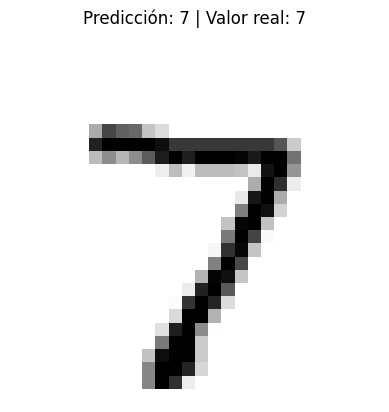

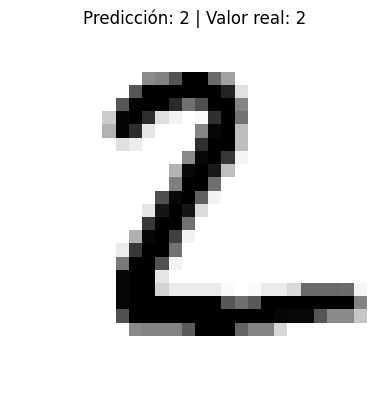

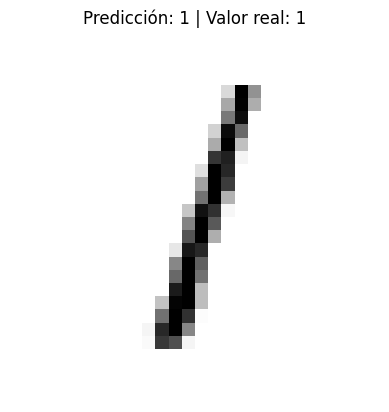

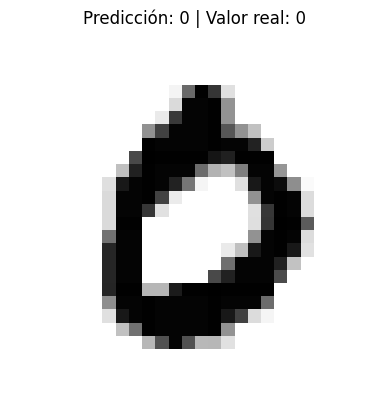

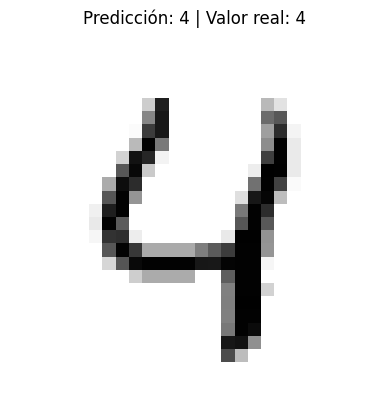

In [15]:
#Realizar 5 predicciones y mostrar resultados
predictions = model.predict(test_data[:5])
for i in range(5):
    plt.imshow(test_data[i].reshape(28,28), cmap=plt.cm.binary)
    plt.title(f"Predicción: {class_names[np.argmax(predictions[i])]} | Valor real: {class_names[test_labels[i]]}")
    plt.axis('off')
    plt.show()